<a href="https://colab.research.google.com/github/SaiAryanV6/pixelpick/blob/main/pixelpick.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
from google.colab import drive
drive.mount("/content/drive")

import glob
import os
import time
import pandas as pd

# Look for steam_games.csv in My Drive and in folders up to 3 levels down
found = []
for pattern in ["", "*/", "*/*/", "*/*/*/"]:
    found = found + glob.glob("/content/drive/MyDrive/" + pattern + "steam_games.csv")

if len(found) == 0:
    print("❌ Can't find steam_games.csv in your Drive. Upload it next to this notebook and run this cell again.")
else:
    FOLDER = os.path.dirname(found[0]) + "/"
    games = pd.read_csv(FOLDER + "steam_games.csv")
    print(f"✅ Loaded {len(games)} games from:", FOLDER)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Loaded 1000 games from: /content/drive/MyDrive/MIST4600/


In [9]:

# Find highly rated games within a customer's budget
def budget_games(games, budget):
    affordable = games[games["price"] <= budget]
    best = affordable.sort_values("pct_pos_total", ascending=False)
    return best[["name", "price", "pct_pos_total"]].head(5)

print(budget_games(games, 20))


                          name  price  pct_pos_total
473  HoloCure - Save the Fans!   0.00             99
54           People Playground   9.99             98
63           Vampire Survivors   4.99             98
399                    OneShot   9.99             98
404             VPet-Simulator   0.00             98


In [2]:

# Find paid games that offer the most playtime for their price
def best_value_games(games):
    paid = games[games["price"] > 0].copy()
    paid["hours_per_dollar"] = paid["avg_playtime_hours"] / paid["price"]
    best = paid.sort_values("hours_per_dollar", ascending=False)
    return best[["name", "price", "avg_playtime_hours", "hours_per_dollar"]].head(5)

print(best_value_games(games))


                                name  price  avg_playtime_hours  \
220                  Killing Floor 2   2.99               546.2   
418                Age of History II   4.99               349.9   
255                   Cookie Clicker   4.99               308.7   
4    Tom Clancy's Rainbow Six® Siege   3.99               236.7   
579                    Bright Memory   7.99               346.7   

     hours_per_dollar  
220        182.675585  
418         70.120240  
255         61.863727  
4           59.323308  
579         43.391740  


In [3]:

# Sub-question 3: Which affordable games have the best ratings and playtime?
def best_overall_games(games, budget):
    affordable = games[games["price"] <= budget].copy()
    best = affordable.sort_values(
        ["pct_pos_total", "avg_playtime_hours"],
        ascending=[False, False]
    )
    return best[["name", "price", "pct_pos_total", "avg_playtime_hours"]].head(5)

print(best_overall_games(games, 20))


                          name  price  pct_pos_total  avg_playtime_hours
473  HoloCure - Save the Fans!   0.00             99                 0.0
13              Stardew Valley  14.99             98                81.2
54           People Playground   9.99             98                51.1
63           Vampire Survivors   4.99             98                38.2
320                Pizza Tower  19.99             98                19.0


In [5]:

# PixelPick class for recommending Steam games
class PixelPickApp:
    def __init__(self, games):
        self.games = games

    def recommend(self, budget):
        return best_overall_games(self.games, budget)

# Create the app and use it
app = PixelPickApp(games)
print(app.recommend(20))


                          name  price  pct_pos_total  avg_playtime_hours
473  HoloCure - Save the Fans!   0.00             99                 0.0
13              Stardew Valley  14.99             98                81.2
54           People Playground   9.99             98                51.1
63           Vampire Survivors   4.99             98                38.2
320                Pizza Tower  19.99             98                19.0


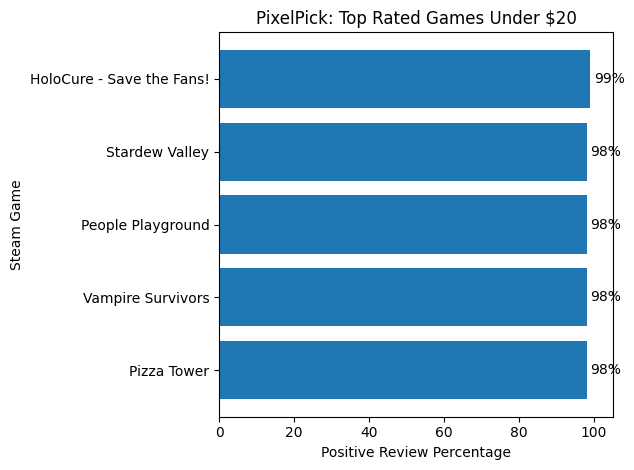

In [7]:


# Outside tool: matplotlib to visualize game recommendations
import matplotlib.pyplot as plt

recommendations = app.recommend(20)

bars = plt.barh(recommendations["name"], recommendations["pct_pos_total"])

plt.xlabel("Positive Review Percentage")
plt.ylabel("Steam Game")
plt.title("PixelPick: Top Rated Games Under $20")
plt.xlim(0, 105)
plt.gca().invert_yaxis()

# Display each game's review percentage
for bar in bars:
    plt.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
             f"{bar.get_width():.0f}%", va="center")

plt.tight_layout()
plt.show()


# PixelPick

My app helps a gaming store decide which games to recommend for customers by comparing prices of games, playtime average, and ratings of players to find games that offer the best quality for their money.